# Laboratorium 0: Python w pracowni zestawów robotycznych

[![Otwórz w Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdoHaha/automation_robotics_lab/blob/master/pl/lab_auto_0.ipynb)

Mała pracownia produkuje zestawy robotyczne **Mini** i **Pro**. Zanim poprosimy solver o wybór planu produkcji, musimy opisać produkty, obliczyć zużycie zasobów, sprawdzić plan i przedstawić wynik na wykresie.

To wprowadzenie do Pythona. Model optymalizacyjny zbudujemy w laboratorium 1, gdzie PuLP wybierze wielkości produkcji. Teraz ilości wybierasz **Ty**, a Python sprawdza ich konsekwencje.

Po wykonaniu ćwiczeń potrafisz:

- zapisywać ilości, etykiety i jednostki w zmiennych;
- porządkować dane modelu w listach, słownikach i tabelach;
- obliczać sumy za pomocą pętli, wyrażeń składanych i `sum`;
- napisać małą funkcję, której wyniki można wykorzystać ponownie;
- używać NumPy, pandas i Matplotlib do sprawdzania i objaśniania planu;
- uruchamiać notebook w sposób powtarzalny i rozpoznawać typowe błędy Pythona.

**Jak pracować:** przy każdym zadaniu stosuj kolejność **przewidź → uruchom → zmień → wyjaśnij**. Zapisuj przewidywania i wyjaśnienia we własnych komórkach Markdown. Kod początkowy działa bez uzupełniania; zadania „DO ZROBIENIA” polegają na rozbudowaniu działających przykładów.

## 1. Uruchamiaj notebook komórka po komórce

**Komórka kodu** wykonuje kod Pythona. **Komórka Markdown** zawiera objaśnienia, takie jak to. Wybierz komórkę i naciśnij **Shift+Enter** lub kliknij ▶, aby ją uruchomić. Środowisko wykonawcze, czyli kernel, pamięta zmienne z wcześniejszych komórek. Najpierw uruchom je od góry do dołu; po zmianie danych uruchom ponownie wszystkie obliczenia, które z nich korzystają.

W Google Colab wybierz **Runtime → Run all** (w polskim interfejsie: **Środowisko wykonawcze → Uruchom wszystko**), aby sprawdzić cały notebook. W lokalnym Jupyterze użyj **Restart Kernel and Run All**. Po instalacji bibliotek przykłady nie wymagają pobierania plików ani danych lokalnych. Komórka przygotowująca środowisko instaluje potrzebne pakiety tylko wtedy, gdy ich brakuje; świeże środowisko może potrzebować internetu do tego jednego kroku. Suwaki są opcjonalne, a każde ćwiczenie można wykonać, zmieniając parametry w komórce kodu.

Poniższe importy nadają bibliotekom krótkie nazwy: `np`, `pd` i `plt`. `display` czytelnie wyświetla tabele zarówno w Colab, jak i w Jupyterze.

In [3]:
# Te moduły służą do sprawdzania i instalowania bibliotek używanych w notebooku.
import importlib.util
import subprocess
import sys

required = ["numpy", "pandas", "matplotlib"]
# Zachowaj tylko nazwy pakietów, których Python nie znajduje w tym środowisku.
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    # sys.executable wybiera Pythona tego notebooka, a nie inną instalację.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import numpy as np  # tablice liczbowe: będziemy używać np.array(...)
import pandas as pd  # tabele: będziemy używać pd.DataFrame(...)
import matplotlib.pyplot as plt  # rysowanie wykresów
from IPython.display import display  # wyświetlanie tabel w notebooku

# Ustaw ten sam domyślny rozmiar wykresów w całym notebooku.
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": False})
print("Gotowe: NumPy, pandas i Matplotlib są dostępne.")

Gotowe: NumPy, pandas i Matplotlib są dostępne.


## 2. Zobacz, jak działa pracownia

Zestaw wymaga najpierw montażu, a następnie testowania. Na każde stanowisko przypada ograniczona liczba minut dostępnych dziś. Ilustrację tworzy kolejna komórka, więc działa ona także bez pobierania obrazka.

**Przewidź:** jakie dane są potrzebne, aby sprawdzić, czy można wyprodukować 4 zestawy Mini i 3 zestawy Pro? Przyjrzyj się schematowi, a następnie prześledź komentarze w kodzie rysującym prostokąty i strzałki.

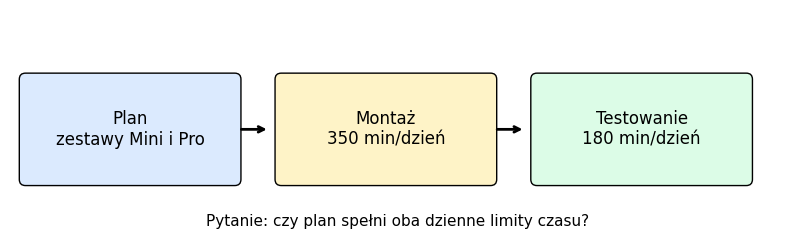

In [4]:
from matplotlib.patches import FancyBboxPatch

# fig to cały rysunek; ax to obszar, w którym rysujemy.
fig, ax = plt.subplots(figsize=(10, 3))
ax.set(xlim=(0, 10), ylim=(0, 3))
ax.axis("off")  # Schemat procesu nie potrzebuje numerowanych osi.
# Każda krotka zawiera pozycję poziomą prostokąta, etykietę i kolor.
boxes = [
    (0.2, "Plan\nzestawy Mini i Pro", "#dbeafe"),
    (3.5, "Montaż\n350 min/dzień", "#fef3c7"),
    (6.8, "Testowanie\n180 min/dzień", "#dcfce7"),
]
for x, label, color in boxes:
    # Narysuj prostokąt, a następnie umieść etykietę w jego środku.
    ax.add_patch(FancyBboxPatch((x, 0.8), 2.7, 1.3,
                               boxstyle="round,pad=0.08", facecolor=color))
    ax.text(x + 1.35, 1.45, label, ha="center", va="center", fontsize=12)
for start, end in [(2.95, 3.35), (6.25, 6.65)]:
    # xytext to początek strzałki, a xy — jej koniec.
    ax.annotate("", xy=(end, 1.45), xytext=(start, 1.45),
                arrowprops={"arrowstyle": "->", "lw": 2})
ax.text(5, 0.2, "Pytanie: czy plan spełni oba dzienne limity czasu?",
        ha="center", fontsize=11)
plt.show()
# Czas montaż pojedynczengo zestawu (Mini, Pro), czas testowania zestawu (Mini, Pro), liczba stanowisk, czas na stanowisku.
# Odpowiedź: W zależności od powyższych danych

## 3. Zmienne, liczby, napisy i jednostki

`=` przypisuje wartość do nazwy; nie oznacza „rozwiąż równanie”. Python rozróżnia liczby całkowite (`int`), liczby zmiennoprzecinkowe (`float`) i tekst (`str`). O jednostki musimy zadbać sami: nazwa `assembly_min_per_kit` przypomina, że liczba oznacza minuty montażu jednego zestawu.

Mnożenie `*` łączy wielkości. Dzielenie `/` może dać wynik niecałkowity. **f-string**, czyli napis formatowany, wstawia wartości do komunikatu; `:.2f` wyświetla dwa miejsca po przecinku. `print` wyświetla komunikat. Sama zmienna na końcu komórki wyświetla swoją wartość.

**Przewidź:** ile wyniesie `assembly_used_min`? W jakich jednostkach?

In [6]:
# Zapisz etykiety i ilości pod nazwami opisującymi ich znaczenie.
product_name = "Mini"
mini_quantity = 4
assembly_min_per_kit = 20
profit_pln_per_kit = 40.0

# Liczba zestawów × czas na zestaw (min/zestaw) daje łączny czas (min).
assembly_used_min = mini_quantity * assembly_min_per_kit
# Wyniesie 80 minut dla Mini.
# 4zestaw*20(min/zestaw), zestaw się skróci i bedą minuty
# Takie samo mnożenie oblicza wkład produktu do zysku.
mini_profit_pln = mini_quantity * profit_pln_per_kit
# f-string wstawia obliczone wartości do czytelnego komunikatu.
print(f"{mini_quantity} zestawów {product_name} zużywa {assembly_used_min} minut montażu.")
print(f"Ich wkład do zysku wynosi {mini_profit_pln:.2f} PLN.")
# type(...).__name__ pokazuje, czy wartość jest tekstem, liczbą całkowitą czy zmiennoprzecinkową.
print("Typy:", type(product_name).__name__, type(mini_quantity).__name__,
      type(profit_pln_per_kit).__name__)

5 zestawów Mini zużywa 100 minut montażu.
Ich wkład do zysku wynosi 200.00 PLN.
Typy: str int float


**Zadanie kontrolne A — zmień i wyjaśnij**

DO ZROBIENIA: zmień `mini_quantity` z 4 na 5 i uruchom komórkę ponownie. Najpierw przewidź nowy czas montażu i zysk. Wyjaśnij, dlaczego mnożenie *min/zestaw × zestawy* daje minuty. Następnie przywróć 4, aby Twój wariant bazowy zgadzał się z dalszymi przykładami.

Uwaga: `"4"` to tekst, a `4` to liczba. `int("4")` zamienia tekst na liczbę całkowitą. Nie mieszaj godzin z minutami ani procentów z ułamkami.

## 4. Listy i słowniki: dane z etykietami

**Lista** przechowuje uporządkowany zbiór elementów. Python numeruje pozycje od zera: `products[0]` to pierwszy produkt. **Słownik** łączy klucz z wartością: `profit_pln["Mini"]` odczytuje zysk według nazwy produktu.

Korzystamy ze słowników, ponieważ sama liczba `40` nie mówi, którego produktu dotyczy. Wielkość liter ma znaczenie: `"Mini"` i `"mini"` to różne klucze. Zachowujemy angielskie identyfikatory w kodzie i tabelach: `assembly` oznacza montaż, `testing` — testowanie, `profit` — zysk, a `capacity` — dostępny zasób. Nazwy produktów Mini i Pro pozostają takie same we wszystkich przykładach.

**Krotka**, np. `("assembly", "Mini")`, przechowuje stałą parę wartości. Klucze będące krotkami przydają się, gdy wartość zależy od dwóch etykiet: zasobu **i** produktu. Ten sposób zapisu wróci w laboratorium o przepływie w sieci jako `(origin, destination)`, czyli para miejsca wysyłki i miejsca odbioru.

In [34]:
# Listy zachowują kolejność używaną w pętlach i na wykresach.
products = ["Mini", "Pro"]
resources = ["assembly", "testing"]
profit_pln = {"Mini": 40, "Pro": 70}             # PLN na zestaw
capacity_min = {"assembly": 350, "testing": 180} # minuty na dzień
time_min = {                                   # minuty na zestaw
    ("assembly", "Mini"): 20,
    ("assembly", "Pro"): 40,
    ("testing", "Mini"): 15,
    ("testing", "Pro"): 10,
}
plan = {"Mini": 4, "Pro": 3}                   # zestawy na dzień

# [0] wybiera pozycję z listy; ["Mini"] wybiera wartość według klucza słownika.
print("Pierwszy produkt:", products[0])
print("Zysk Mini:", profit_pln["Mini"], "PLN/zestaw")
print("Czas montażu Pro:", time_min[("assembly", "Pro")], "min/zestaw")
print("Produkty w planie:", list(plan.keys()))  # keys() pobiera etykiety.
print("Czas testowania Mini:", time_min["testing","Mini"],"min/zestaw")

#Odpowiedź 1 : Zmiana planu nie zmienia czasu potrzebnego na jeden zestaw.
#Odpowiedź 2 : Parametr wpływa na cykl produkcyjny, a ilość nie.

Pierwszy produkt: Mini
Zysk Mini: 40 PLN/zestaw
Czas montażu Pro: 40 min/zestaw
Produkty w planie: ['Mini', 'Pro']
Czas testowania Mini: 15 min/zestaw


**Zadanie kontrolne B — odczytaj dane przed obliczeniem**

DO ZROBIENIA: wyświetl liczbę minut testowania jednego zestawu Mini, odczytując właściwy klucz-krotkę. Następnie zmień tylko `plan["Pro"]` na 4 i wyświetl plan. Czy zmiana planu zmienia czas potrzebny na jeden zestaw? Wyjaśnij różnicę między **parametrem** (danymi wejściowymi) a **decyzją** (ilością, którą możemy wybrać). Przywróć ilość Pro równą 3.

## 5. Pętle, wyrażenia składane i sumy

Pętla `for` powtarza kod z wcięciem dla każdego elementu. Tutaj obliczamy kolejno zysk z poszczególnych produktów, a następnie dodajemy go do sumy za pomocą `+=`.

**Przewidź, licząc ręcznie:** plan bazowy zakłada 4 zestawy Mini i 3 zestawy Pro. Jaki jest łączny zysk? Zapisz sumę dwóch składników przed uruchomieniem komórki.

In [35]:
total_profit_pln = 0  # Ustaw początkową sumę przed wejściem do pętli.
for product in products:
    # Pętla używa kolejno "Mini" i "Pro" jako bieżącego klucza słownika.
    contribution = profit_pln[product] * plan[product]
    print(f"{product}: {contribution} PLN")
    total_profit_pln += contribution  # Dodaj zysk z tego produktu do sumy.
print("Łącznie:", total_profit_pln, "PLN")

Mini: 160 PLN
Pro: 210 PLN
Łącznie: 370 PLN


`sum` dodaje wartości ze zbioru. **Wyrażenie listowe** tworzy listę, zapisując tę samą ideę `for` w jednym wierszu. **Wyrażenie słownikowe** tworzy wynik z etykietami. Czytaj skrócony zapis tak: „dla każdego zasobu zsumuj czas na zestaw × liczbę zestawów po wszystkich produktach”.

Poniższe wyrażenia używają tych samych danych co pętla; nie szukają najlepszego planu. W PuLP podobna funkcja `lpSum` będzie łączyć wyrażenia zawierające nieznane zmienne decyzyjne.

In [37]:
from IPython.core.logger import time
# Zbuduj listę wkładów do zysku, po jednym na produkt.
contributions = [profit_pln[p] * plan[p] for p in products]
profit_from_sum = sum(contributions)
# Dla każdego zasobu r zsumuj czas zużyty przez wszystkie produkty p.
used_min = {
    r: sum(time_min[(r, p)] * plan[p] for p in products)
    for r in resources
}
laczny_czas_testowania=0
for resource in resources:
    for product in products:
        if resource == "testing":
            czas = time_min[resource, product] * plan[product]
            laczny_czas_testowania += czas


print("czas testing:",laczny_czas_testowania, "min")
print("Wkłady produktów do zysku:", contributions)
print("Zysk:", profit_from_sum, "PLN")
print("Zużycie zasobów:", used_min, "minuty")
# assert zgłasza błąd, jeśli te dwa sposoby obliczenia sumy dają różne wyniki.
assert profit_from_sum == total_profit_pln

#Odpowiedz: Zewnetrzna petla wybiera z tabeli rodzaj zasobu, a petla wewnetrzna liczy laczny czas

czas testing: 90 min
Wkłady produktów do zysku: [160, 210]
Zysk: 370 PLN
Zużycie zasobów: {'assembly': 200, 'testing': 90} minuty


**Zadanie kontrolne C — rozwiń skrócony zapis**

DO ZROBIENIA: oblicz ręcznie zużycie czasu testowania w planie bazowym. Zastąp wyrażenie słownikowe dwiema zagnieżdżonymi pętlami `for` i porównaj wyniki. Wyjaśnij, co robi zewnętrzna pętla po zasobach, a co wewnętrzna pętla po produktach.

## 6. Warunki: czy plan jest dopuszczalny?

Wartość logiczna to `True` lub `False`. Porównania, takie jak `<=`, dają wartości logiczne; `==` sprawdza równość. `and` wymaga spełnienia obu warunków. `all` sprawdza każdy element zbioru. `if` i `else` wybierają, który kod wykonać.

Plan jest **dopuszczalny**, jeśli ilości są nieujemne i żaden limit zasobu nie jest przekroczony. **Luz ograniczenia** (`slack`) to dostępny czas minus zużycie, w minutach. Zerowy luz oznacza pełne wykorzystanie zasobu; ujemny wynik tej różnicy oznacza przekroczenie limitu.

In [38]:
# all(...) daje True tylko wtedy, gdy każda ilość spełnia warunek.
nonnegative = all(plan[p] >= 0 for p in products)
# Porównaj zużyte minuty z limitem każdego zasobu.
within_capacity = all(used_min[r] <= capacity_min[r] for r in resources)
feasible = nonnegative and within_capacity  # Oba warunki muszą być spełnione.

for resource in resources:
    slack = capacity_min[resource] - used_min[resource]  # Niewykorzystane minuty.
    print(f"{resource}: zużycie {used_min[resource]}; luz {slack} min")

# W zależności od wartości logicznej feasible wykona się tylko jedna gałąź.
if feasible:
    print("Plan mieści się w dostępnych dziś zasobach.")
else:
    print("Plan wymaga poprawy: sprawdź ilości i limity zasobów.")

assembly: zużycie 200; luz 150 min
testing: zużycie 90; luz 90 min
Plan mieści się w dostępnych dziś zasobach.


## 7. Funkcje: nazwij obliczenie i wykorzystuj je ponownie

**Funkcja** to nazwany fragment kodu, który możemy uruchamiać z różnymi danymi wejściowymi. Zamiast przepisywać `quantity * profit_per_kit` dla każdego produktu, umieszczamy to obliczenie w funkcji `product_profit`.

`def` rozpoczyna **definicję**. Nazwy w nawiasach to **parametry**: miejsca na dane wejściowe. Wiersze z wcięciem tworzą **ciało funkcji**. Definicja zapisuje instrukcje, ale jeszcze nie oblicza wyniku. **Wywołanie**, np. `product_profit(4, 40)`, wykonuje te instrukcje dla przekazanych wartości, nazywanych **argumentami**.

`return` przekazuje wynik z powrotem do miejsca wywołania. Możemy zapisać go w zmiennej i użyć w dalszych obliczeniach. `print` wyświetla tekst, ale nie zwraca wyświetlanej wartości. Funkcja bez `return` zwraca `None`.

Pierwszy napis w funkcji to jej **docstring**, czyli tekst dokumentujący. Objaśnia cel, dane wejściowe, jednostki i zwracany wynik. Możesz go odczytać, wpisując `help(product_profit)` w komórce kodu.

In [39]:
def product_profit(quantity, profit_per_kit=40):
    """Zwróć wkład jednego produktu do zysku, w PLN.

    Argumenty:
        quantity: Liczba zestawów w wybranym planie.
        profit_per_kit: Zysk w PLN na zestaw; domyślnie 40, jeśli pominięty.

    Wynik:
        Ilość pomnożona przez jednostkowy zysk, w PLN.
    """
    # Te nazwy parametrów oznaczają argumenty przekazane w tym wywołaniu.
    contribution = quantity * profit_per_kit
    return contribution  # Zwróć liczbę, zamiast tylko ją wyświetlić.

# Wywołanie wykonuje ciało funkcji. Każde wywołanie może przekazać inne dane.
mini_contribution = product_profit(4)  # Pominięty zysk jednostkowy przyjmuje domyślną wartość 40.
pro_contribution = product_profit(quantity=3, profit_per_kit=70)  # Argumenty nazwane.
my_contribution = product_profit(5, 70)
print("Moja:", my_contribution, "PLN")
print("Mini:", mini_contribution, "PLN")
print("Pro:", pro_contribution, "PLN")
print("Razem:", mini_contribution + pro_contribution, "PLN")

#Quantity = 5, profit_per_kit =70
#Wtedy quantity = 5, a profit_per_kit=40, tak jak został zdefiniowany na początku

Moja: 350 PLN
Mini: 160 PLN
Pro: 210 PLN
Razem: 370 PLN


**Wypróbuj wywołanie funkcji:** dodaj komórkę wywołującą `product_profit(5, 70)` i zapisz wynik jako `my_contribution`. Wyświetl tę zmienną. Jakie wartości są podstawiane za `quantity` i `profit_per_kit`? Co zmienia wywołanie `product_profit(5)`? Dodawaj docstring do funkcji, które piszesz samodzielnie.

### Funkcja sprawdzająca cały plan

`evaluate_plan` łączy obliczenia sum i sprawdzanie warunków z poprzednich komórek. Przyjmuje cztery słowniki: wybrane ilości, zysk na zestaw, czas na zestaw i dostępne minuty. Zwraca kolejny słownik zawierający zysk, zużycie zasobów, luz ograniczeń i informację, czy plan mieści się w limitach.

Zmienne `use`, `slack` i `feasible` są **lokalne**: należą do konkretnego wywołania funkcji. Zwracany słownik udostępnia te odpowiedzi poza funkcją. Prześledź obliczenia zgodnie z numerowanymi komentarzami.

In [43]:
def evaluate_plan(candidate, profits, times, capacities):
    """Oblicz zysk i sprawdź, czy wybrany plan mieści się w limitach.

    Argumenty:
        candidate: Słownik nazw produktów i wybranych liczb zestawów.
        profits: Słownik nazw produktów i zysku w PLN na zestaw.
        times: Słownik par (zasób, produkt) i czasu w minutach na zestaw.
        capacities: Słownik nazw zasobów i dostępnych minut dziennie.

    Wynik:
        Słownik z polami profit_pln, used_min, slack_min i feasible.
        Dopuszczalność oznacza nieujemne ilości i zachowanie limitów zasobów.
    """
    # 1. Dla każdego zasobu zsumuj czas na zestaw × wybraną ilość.
    use = {
        r: sum(times[(r, p)] * candidate[p] for p in profits)
        for r in capacities
    }
    # 2. Dla każdego zasobu odejmij zużyte minuty od dostępnych minut.
    slack = {r: capacities[r] - use[r] for r in capacities}
    # 3. Odrzuć ujemne ilości lub przeciążenie zasobu.
    feasible = (all(q >= 0 for q in candidate.values())
                and all(value >= -1e-9 for value in slack.values()))
    # 4. Zwróć wyniki z etykietami, aby można je było wybierać i wykorzystać ponownie.
    return {
        "profit_pln": sum(profits[p] * candidate[p] for p in profits),
        "used_min": use,
        "slack_min": slack,
        "feasible": feasible,
    }

# Ta sama funkcja sprawdza dwa różne plany; żadne wywołanie nie zmienia danych.
baseline = evaluate_plan(plan, profit_pln, time_min, capacity_min)
overloaded = evaluate_plan({"Mini": 8, "Pro": 5}, profit_pln, time_min, capacity_min)
print("Wariant bazowy:", baseline)
print("Plan przeciążający zasoby:", overloaded)

my_result=evaluate_plan({"Mini": 6, "Pro": 2},profit_pln, time_min, capacity_min)
print("Moje wyniki:", my_result)
print("Moje wyniki:", my_result["profit_pln"])

#Ten plan przekracza mozliwosci przedsiebiorstwa, nasz czas montazu maksymalny na stanowisko wynosi 350min/dzien, a tutaj wyszlo 360.

Wariant bazowy: {'profit_pln': 370, 'used_min': {'assembly': 200, 'testing': 90}, 'slack_min': {'assembly': 150, 'testing': 90}, 'feasible': True}
Plan przeciążający zasoby: {'profit_pln': 670, 'used_min': {'assembly': 360, 'testing': 170}, 'slack_min': {'assembly': -10, 'testing': 10}, 'feasible': False}
Moje wyniki: {'profit_pln': 380, 'used_min': {'assembly': 200, 'testing': 110}, 'slack_min': {'assembly': 150, 'testing': 70}, 'feasible': True}
Moje wyniki: 380


Mała tolerancja `-1e-9` uwzględnia drobne błędy zaokrągleń przy obliczeniach na wartościach zmiennoprzecinkowych. To jedna miliardowa minuty, a nie zgoda na istotne przekroczenie dostępnego czasu. Dla naszych całkowitych danych wejściowych obliczenia są dokładne.

**Zadanie kontrolne D — zwracanie wyniku a wyświetlanie**

DO ZROBIENIA: wywołaj `evaluate_plan` dla `{"Mini": 6, "Pro": 2}`, zapisz zwrócony wynik jako `my_result` i wyświetl `my_result["profit_pln"]`. Wyjaśnij, dlaczego wysoki zysk planu niedopuszczalnego nie uzasadnia jego rekomendowania. Funkcja sprawdzająca dopuszcza ilości ułamkowe, podobnie jak ciągły model LP; wymóg produkcji całych zestawów będzie później wymagać całkowitoliczbowych zmiennych decyzyjnych.

## 8. Tabele w pandas

`DataFrame` biblioteki pandas to tabela. Ułatwia sprawdzanie jednostek i porównywanie wierszy. Lista słowników tworzy po jednym wierszu na słownik. Nawiasy kwadratowe wybierają kolumnę, a działania na kolumnie obejmują każdy jej wiersz.

Z naszych słowników zbudujemy tabelę produktów, a z wyniku funkcji — osobną tabelę sprawdzającą zasoby. **Przewidź:** który zasób będzie miał mniejszy luz ograniczenia?

In [44]:
# Każdy słownik staje się wierszem tabeli; pętla tworzy wiersz na każdy produkt.
product_table = pd.DataFrame([
    {"product": p, "quantity_kits": plan[p], "profit_pln_per_kit": profit_pln[p],
     "assembly_min_per_kit": time_min[("assembly", p)],
     "testing_min_per_kit": time_min[("testing", p)]}
    for p in products
])
# Mnożenie dwóch wybranych kolumn działa wiersz po wierszu.
product_table["contribution_pln"] = (product_table["quantity_kits"]
                                     * product_table["profit_pln_per_kit"])
# Wykorzystaj wyniki funkcji, aby pokazać po jednym wierszu kontrolnym na zasób.
resource_table = pd.DataFrame([
    {"resource": r, "used_min": baseline["used_min"][r],
     "capacity_min": capacity_min[r], "slack_min": baseline["slack_min"][r]}
    for r in resources
])
display(product_table)  # Wyświetl sformatowaną tabelę zamiast zwykłego tekstu.
display(resource_table)
print("Zysk obliczony z tabeli:", product_table["contribution_pln"].sum(), "PLN")

,product,quantity_kits,profit_pln_per_kit,assembly_min_per_kit,testing_min_per_kit,contribution_pln
0,Mini,4,40,20,15,160
1,Pro,3,70,40,10,210


,resource,used_min,capacity_min,slack_min
0,assembly,200,350,150
1,testing,90,180,90


Zysk obliczony z tabeli: 370 PLN


### Mały przykład CSV — bez pobierania pliku

**CSV** to zwykły tekst z wierszami i wartościami rozdzielonymi przecinkami. `StringIO` pozwala pandas czytać tekst tak, jak otwarty plik. Pierwszy wiersz podaje nazwy kolumn. To niezależny przykład odczytu danych: nie zastępuje naszych słowników pracowni.

Później możesz użyć `pd.read_csv("my_products.csv")` z własnym plikiem lokalnym lub przesłanym do środowiska. W Colab przesyłanie pliku jest opcjonalne; wystarczy poniższy CSV zapisany w kodzie. Angielskie nazwy kolumn odpowiadają nazwom danych używanym w pozostałych przykładach.

In [45]:
from io import StringIO

csv_text = """product,profit_pln_per_kit,assembly_min_per_kit,testing_min_per_kit
Mini,40,20,15
Pro,70,40,10
"""
# StringIO przekazuje nasz tekst do read_csv jak plik zapisany w pamięci.
csv_table = pd.read_csv(StringIO(csv_text))
display(csv_table)
# .loc[etykieta wiersza, etykieta kolumny] wybiera jedną wartość; tutaj etykietą wiersza jest 0.
print("Zysk w pierwszym wierszu:", csv_table.loc[0, "profit_pln_per_kit"], "PLN/zestaw")

,product,profit_pln_per_kit,assembly_min_per_kit,testing_min_per_kit
0,Mini,40,20,15
1,Pro,70,40,10


Zysk w pierwszym wierszu: 40 PLN/zestaw


## 9. Tablice NumPy i opisane wykresy

**Tablica** NumPy przechowuje wartości liczbowe. W przeciwieństwie do mnożenia listy Pythona, mnożenie tablicy liczbowej wykonuje działania na jej elementach. Pilnuj kolejności: tutaj pozycje odpowiadają `products = ["Mini", "Pro"]`.

**Budowa wykresu:** `fig, ax = plt.subplots()` tworzy całą figurę (`fig`) i obszar rysowania (`ax`). `ax.bar(x, height)` rysuje słupki; `ax.plot(x, y)` narysowałoby linię. `ax.set(...)` dodaje tytuł i opisy osi. `plt.show()` wyświetla wynik. Najpierw narysuj wkład poszczególnych produktów do zysku.

Tablice: [4 3] [40 70]
Iloczyn element po elemencie: [160 210]


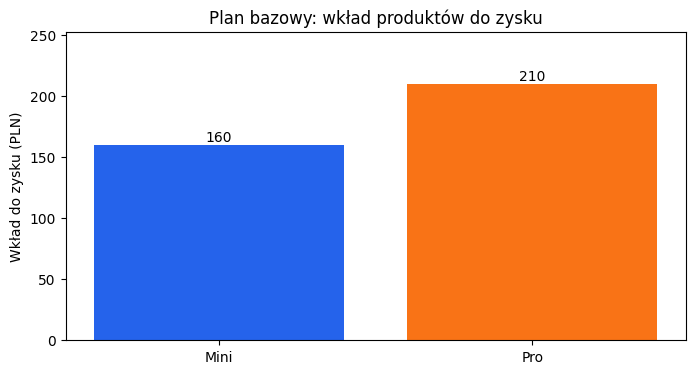

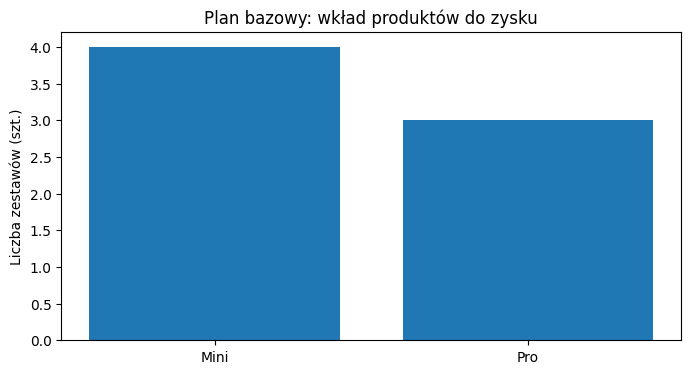

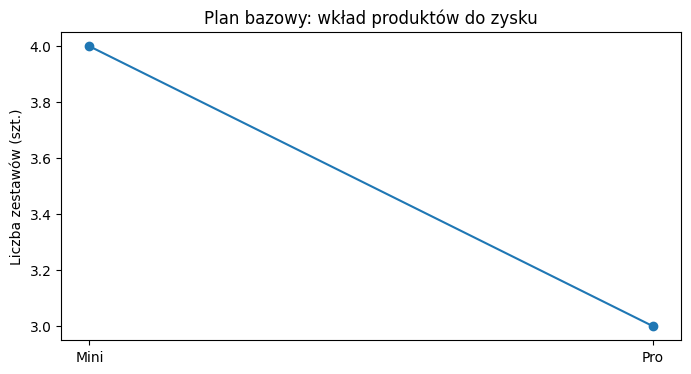

In [48]:
# Zachowaj tę samą kolejność ilości i zysków jednostkowych: Mini, następnie Pro.
quantities = np.array([plan[p] for p in products])
unit_profits = np.array([profit_pln[p] for p in products])
profit_contributions = quantities * unit_profits  # Pomnóż odpowiadające sobie elementy.
print("Tablice:", quantities, unit_profits)
print("Iloczyn element po elemencie:", profit_contributions)

fig, ax = plt.subplots()  # Utwórz figurę i jej obszar rysowania.
bars = ax.bar(products, profit_contributions, color=["#2563eb", "#f97316"])
ax.bar_label(bars, fmt="%.0f")  # Wpisz każdą wartość nad jej słupkiem.
ax.set(title="Plan bazowy: wkład produktów do zysku", ylabel="Wkład do zysku (PLN)")
ax.set_ylim(0, max(profit_contributions) * 1.2)  # Zostaw miejsce nad etykietami.
plt.show()

fig, ax = plt.subplots()
ax.bar(product_table["product"], product_table["quantity_kits"])
ax.set(title="Plan bazowy: wkład produktów do zysku", ylabel="Liczba zestawów (szt.)")
plt.show()

fig, ax = plt.subplots()
#ax.bar(product_table["product"], product_table["quantity_kits"])
ax.plot(product_table["product"], product_table["quantity_kits"], marker ="o")
ax.set(title="Plan bazowy: wkład produktów do zysku", ylabel="Liczba zestawów (szt.)")
plt.show()

#Osobne slupki fizycznie rozdzielaja produkty (Mini, Pro), falszywa ciaglosc linii,

**Zbuduj własny wykres**

DO ZROBIENIA: dodaj nową komórkę kodu. Użyj `fig, ax = plt.subplots()` oraz `ax.bar(product_table["product"], product_table["quantity_kits"])`, aby narysować ilości zamiast zysku. Dodaj tytuł, opis osi y **Liczba zestawów (szt.)** i `plt.show()`. Następnie zastąp `ax.bar` przez `ax.plot(..., marker="o")` i wyjaśnij, dlaczego słupki lepiej niż linia przedstawiają oddzielne kategorie produktów.

### Od wywołania funkcji do tabeli i wykresu

`show_plan` łączy sprawdzanie planu z rysowaniem. Jej cztery parametry to liczba zestawów Mini, liczba zestawów Pro, dostępne minuty montażu i dostępne minuty testowania. W zapisie `mini=4` liczba **4 jest wartością domyślną argumentu**: `show_plan()` jej używa, a `show_plan(mini=6)` zastępuje ją liczbą 6 w tym wywołaniu. Parametry z wartościami domyślnymi nadal można przekazywać pozycyjnie lub po nazwie.

Prześledź numerowane kroki w ciele funkcji: zbuduj słowniki wejściowe, wywołaj `evaluate_plan`, ułóż odpowiedzi w tabeli, przelicz zużycie na procent dostępnego zasobu, narysuj wykres i zwróć słownik wyników. Funkcja korzysta z `profit_pln`, `time_min` i `resources` z wcześniejszych komórek; uruchom je przed jej wywołaniem.

Linia przerywana oznacza **100% dostępnego czasu**. Słupki wychodzące ponad nią pokazują przeciążenie. Odczytaj także kontrolne wartości liczbowe: sam wykres nie dowodzi dopuszczalności. Definicja `show_plan` w kolejnej komórce jeszcze nie wyświetla planu; dopiero następna komórka parametrów ją **wywołuje**. Funkcja nie zmienia planu bazowego.

In [54]:
def show_plan(mini=4, pro=3, assembly_capacity=350, testing_capacity=180):
    """Sprawdź plan, wyświetl zużycie zasobów i zwróć wyniki.

    Argumenty:
        mini: Liczba zestawów Mini; domyślnie 4.
        pro: Liczba zestawów Pro; domyślnie 3.
        assembly_capacity: Dodatnie dostępne minuty montażu; domyślnie 350.
        testing_capacity: Dodatnie dostępne minuty testowania; domyślnie 180.

    Wynik:
        Słownik z evaluate_plan: profit_pln, used_min, slack_min i feasible.
        Funkcja wyświetla też tabelę kontrolną i wykres wykorzystania zasobów.

    Korzysta z wcześniej zdefiniowanych profit_pln, time_min i resources.
    """
    # 1. Zapisz cztery argumenty wywołania w słownikach funkcji sprawdzającej.
    candidate = {"Mini": mini, "Pro": pro}
    capacities = {"assembly": assembly_capacity, "testing": testing_capacity}
    # 2. Wywołaj funkcję sprawdzającą i zapisz zwrócony słownik.
    result = evaluate_plan(candidate, profit_pln, time_min, capacities)
    # 3. Z obliczonych wyników zbuduj po jednym wierszu na zasób.
    table = pd.DataFrame([
        {"resource": r, "used_min": result["used_min"][r],
         "capacity_min": capacities[r], "slack_min": result["slack_min"][r]}
        for r in resources
    ])
    display(table)
    print(f"Plan: {candidate}; zysk {result['profit_pln']:.0f} PLN; "
          f"dopuszczalny: {result['feasible']}")
    # 4. Zużycie / dostępny czas × 100 przelicza minuty na procent dostępnego zasobu.
    utilization = np.array([result["used_min"][r] / capacities[r] * 100
                            for r in resources])
    # 5. Narysuj procenty; przeciążony zasób zaznacz na czerwono.
    fig, ax = plt.subplots()
    colors = ["#2563eb" if value <= 100 + 1e-9 else "#dc2626"
              for value in utilization]
    bars = ax.bar(resources, utilization, color=colors)
    ax.bar_label(bars, fmt="%.1f%%")  # %.1f pokazuje jedno miejsce po przecinku; %% wyświetla znak procentu.
    ax.axhline(100, color="black", linestyle="--", label="Dostępny zasób = 100%")  # Linia odniesienia.
    ax.set(title=f"Zużycie zasobów dla Mini={mini}, Pro={pro}",
           ylabel="Zużycie / dostępny zasób (%)", ylim=(0, max(120, utilization.max() * 1.2)))
    ax.legend()
    plt.show()
    return result  # 6. Udostępnij liczby do dalszego wykorzystania oprócz pokazania wykresu.

### Wariant bez suwaków: zmień parametr i uruchom ponownie

To pełny sposób wykonania ćwiczenia interaktywnego również wtedy, gdy suwaki są niedostępne. Zmień cztery wartości poniżej, uruchom komórkę ponownie i sprawdź odświeżoną tabelę oraz wykres. Dostępny czas musi być dodatni. W przypadku ilości zacznij od liczb całkowitych.

**Przewidź:** jeśli wyprodukujemy jeden zestaw Pro więcej, zużycie którego zasobu wzrośnie szybciej?

,resource,used_min,capacity_min,slack_min
0,assembly,480,670,190
1,testing,180,30,-150


Plan: {'Mini': 6, 'Pro': 9}; zysk 870 PLN; dopuszczalny: False


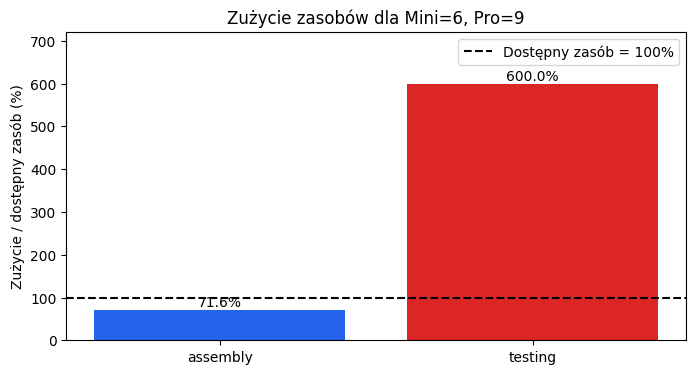

In [55]:
# Te argumenty przekażemy do show_plan; zmień jeden i uruchom komórkę ponownie.
mini_to_try = 6
pro_to_try = 9
assembly_capacity_to_try = 670
testing_capacity_to_try = 30

# Wywołanie wykonuje teraz ciało funkcji i zapisuje zwrócony słownik.
trial_result = show_plan(mini_to_try, pro_to_try,
                         assembly_capacity_to_try, testing_capacity_to_try)

### Zbuduj pierwszy suwak: dane wejściowe → funkcja → wykres

Suwak przekazuje dane wejściowe, nie rozwiązuje modelu. `widgets.IntSlider` wybiera liczbę całkowitą. `value`, `min`, `max` i `step` określają wartość początkową i zakres. `continuous_update=False` odświeża wykres dopiero po puszczeniu suwaka, zamiast tworzyć wiele wykresów podczas przeciągania.

Poniższy przykład zaczyna od **jednego** suwaka. Parametr funkcji nazywa się `mini`, więc `widgets.interact` musi otrzymać odpowiadający mu argument nazwany `mini=...`. `interact` wywołuje funkcję od razu, a następnie przy każdej zmianie wartości. Funkcja za każdym razem oblicza i rysuje nowe wyniki.

Bez suwaków `plot_mini_profit(4)` wywołuje dokładnie tę samą funkcję. Samo utworzenie suwaka nie odświeży żadnego wykresu; interakcję zapewnia połączenie go z funkcją wywoływaną po zmianie wartości, czyli funkcją zwrotną (callback).

In [58]:
def plot_mini_profit(mini=4):
    """Wyświetl wkład zestawów Mini do zysku i narysuj jeden słupek.

    Argumenty:
        mini: Wybrana liczba zestawów Mini; domyślnie 4.

    Korzysta z profit_pln["Mini"] (PLN na zestaw) z wcześniejszej komórki danych.
    Zwraca None: wyświetla wyniki, zamiast zwracać liczby.
    """
    # Przy każdym wywołaniu funkcji oblicz nowy wkład do zysku.
    contribution = profit_pln["Mini"] * mini
    print(f"{mini} zestawów Mini daje wkład do zysku {contribution} PLN.")
    fig, ax = plt.subplots(figsize=(5, 3))  # Nowy wykres dla tego wywołania.
    ax.bar(["Mini"], [contribution], color="#2563eb")
    ax.set(title="Suwak zmienia ilość i odświeża wykres",
           ylabel="Wkład do zysku (PLN)", ylim=(0, 800))
    plt.show()

# Zaimportuj bibliotekę suwaków, jeśli jest dostępna; w przeciwnym razie wywołaj funkcję bezpośrednio.
try:
    import ipywidgets as widgets
except ImportError:
    print("Opcjonalne kontrolki są niedostępne; wywołaj bezpośrednio plot_mini_profit(4).")
    plot_mini_profit(4)
else:
    try:
        from google.colab import output
        output.enable_custom_widget_manager()  # Włącz wyświetlanie kontrolek w Colab.
    except ImportError:
        pass
    # Utworzenie suwaka opisuje dane wejściowe; jeszcze nie łączy go z wykresem.
    mini_slider = widgets.IntSlider(value=4, min=0, max=20, step=1,
                                    description="Zestawy Mini", continuous_update=False)
    # Dopasuj argument nazwany mini do parametru funkcji o tej samej nazwie.
    first_interaction = widgets.interact(plot_mini_profit, mini=mini_slider)

    def plot_two_profits(mini=4, pro = 3):
        """Wyświetl wkład zestawów Mini do zysku i narysuj jeden słupek.

        Argumenty:
            mini: Wybrana liczba zestawów Mini; domyślnie 4.

        Korzysta z profit_pln["Mini"] (PLN na zestaw) z wcześniejszej komórki danych.
        Zwraca None: wyświetla wyniki, zamiast zwracać liczby.
        """
        # Przy każdym wywołaniu funkcji oblicz nowy wkład do zysku.
        contribution = profit_pln["Mini"] * mini
        print(f"{mini} zestawów Mini daje wkład do zysku {contribution} PLN.")
        contribution2 = profit_pln["Pro"] * pro
        print(f"{pro} zestawów Pro daje wkład do zysku {contribution2} PLN.")
        fig, ax = plt.subplots(figsize=(5, 3))  # Nowy wykres dla tego wywołania.
        ax.bar(["Mini"], [contribution], color="#2563eb")
        ax.bar(["Pro"], [contribution], color="#2333eb")
        ax.set(title="Suwak zmienia ilość i odświeża wykres",
              ylabel="Wkład do zysku (PLN)", ylim=(0, 800))
        plt.show()

interactive(children=(IntSlider(value=4, continuous_update=False, description='Zestawy Mini', max=20), Output(…

In [59]:
def plot_two_profits(mini=4, pro=3):
    """Wyświetl wkład zestawów Mini i Pro do zysku na wspólnym wykresie.

    Argumenty:
        mini: Wybrana liczba zestawów Mini; domyślnie 4.
        pro: Wybrana liczba zestawów Pro; domyślnie 3.
    """
    # Oblicz zysk dla obu produktów
    contribution_mini = profit_pln["Mini"] * mini
    contribution_pro = profit_pln["Pro"] * pro

    print(f"{mini} zestawów Mini daje wkład: {contribution_mini} PLN.")
    print(f"{pro} zestawów Pro daje wkład: {contribution_pro} PLN.")
    print(f"Suma zysku: {contribution_mini + contribution_pro} PLN.")

    # Utwórz wykres z dwoma słupkami
    fig, ax = plt.subplots(figsize=(6, 4))
    bars = ax.bar(["Mini", "Pro"], [contribution_mini, contribution_pro], color=["#2563eb", "#f97316"])
    ax.bar_label(bars, fmt="%.0f PLN")
    ax.set(title="Wkład obu produktów do zysku",
           ylabel="Wkład do zysku (PLN)",
           ylim=(0, 1000))
    plt.show()

# Przygotowanie interaktywnych suwaków
try:
    import ipywidgets as widgets
except ImportError:
    print("Suwaki są niedostępne. Wywołuję bezpośrednio plot_two_profits(4, 3).")
    plot_two_profits(4, 3)
else:
    try:
        from google.colab import output
        output.enable_custom_widget_manager()
    except ImportError:
        pass

    mini_slider = widgets.IntSlider(value=4, min=0, max=20, step=1, description="Zestawy Mini", continuous_update=False)
    pro_slider = widgets.IntSlider(value=3, min=0, max=15, step=1, description="Zestawy Pro", continuous_update=False)

    # Połączenie obu suwaków z funkcją
    widgets.interact(plot_two_profits, mini=mini_slider, pro=pro_slider)


    #Wartosc otrzymuje parametr pro w funkcji plot_two_profits, zwiekszenie ilosci pro o jeden zestaw zwieksza o 70zl

interactive(children=(IntSlider(value=4, continuous_update=False, description='Zestawy Mini', max=20), IntSlid…

**DO ZROBIENIA: samodzielnie zbuduj drugą kontrolkę.** Skopiuj mały działający przykład do nowej komórki. Nazwij funkcję `plot_two_profits(mini=4, pro=3)`. Oblicz wkłady obu produktów do zysku i narysuj dwa słupki. Uzupełnij docstring o objaśnienie obu parametrów ilościowych. Utwórz drugi `IntSlider` dla Pro i połącz oba przez `widgets.interact(plot_two_profits, mini=mini_slider, pro=pro_slider)`. Jeśli suwaki są niedostępne, wywołaj `plot_two_profits(4, 3)` i zmieniaj argumenty.

Przewidź, co zmienia zwiększenie ilości Pro o jeden zestaw. Wyjaśnij, który parametr funkcji otrzymuje tę wartość. Opcjonalnie dodaj trzecią kontrolkę dla założonego zysku na zestaw Pro i odróżnij zmianę ilości od zmiany założenia biznesowego. Zachowaj oryginalny słownik `profit_pln` bez zmian.

### Pełny panel eksperymentów: kontrolki i wspólny obszar wyników

Poniższy panel używa `widgets.interactive_output` zamiast `interact`: słownik łączy **nazwy parametrów** z kontrolkami, a `VBox` układa kontrolki pionowo. `interactive_output` wiąże je z funkcją zwrotną i umieszcza odświeżane wyniki w jednym obszarze. Funkcja zwrotna `update_plan` przekazuje argumenty do `show_plan`.

Ta komórka wywołuje `show_plan` po zmianie suwaka, zastępując tabelę i wykres w swoim obszarze wyników. Nie zmienia `plan` ani tabel bazowych. Gdy jest dostępny, włączamy menedżer widgetów Colab. Jeśli kontrolki nie pojawiają się lub brakuje pakietu, użyj poprzedniej komórki parametrów; wykonanie ćwiczenia nie zależy od suwaków. Opcjonalnie możesz zainstalować `ipywidgets` we własnym środowisku przez `%pip install -q ipywidgets`.

In [65]:
try:
    import ipywidgets as widgets
except ImportError:
    print("Opcjonalne kontrolki są niedostępne; zmień poprzednią komórkę parametrów.")
else:
    try:
        from google.colab import output
        output.enable_custom_widget_manager()
    except ImportError:
        pass  # Lokalny Jupyter nie potrzebuje menedżera kontrolek Colab.

    def update_plan(mini, pro, assembly_capacity, testing_capacity):
        """Odśwież plan na podstawie czterech wartości z kontrolek.

        Argumenty:
            mini: Liczba Mini z jej suwaka.
            pro: Liczba Pro z jej suwaka.
            assembly_capacity: Dostępne minuty montażu z suwaka.
            testing_capacity: Dostępne minuty testowania z suwaka.

        Zwraca None; show_plan wyświetla odświeżoną tabelę i wykres.
        """
        # Przekaż wartości suwaków do tej samej funkcji co w komórce parametrów.
        show_plan(mini, pro, assembly_capacity, testing_capacity)

    # Każdy klucz musi odpowiadać nazwie parametru update_plan.
    controls = {
        "mini": widgets.IntSlider(value=4, min=0, max=20, description="Zestawy Mini",
                                  continuous_update=False),
        "pro": widgets.IntSlider(value=3, min=0, max=12, description="Zestawy Pro",
                                 continuous_update=False),
        "assembly_capacity": widgets.IntSlider(value=350, min=100, max=700, step=10,
                                                description="Montaż (min)",
                                                continuous_update=False),
        "testing_capacity": widgets.IntSlider(value=180, min=60, max=360, step=15,
                                               description="Testy (min)",
                                               continuous_update=False),
    }
    # Połącz zmiany danych z funkcją zwrotną i przechwyć jej wyświetlane wyniki.
    live_output = widgets.interactive_output(update_plan, controls)
    # VBox układa kontrolki; live_output wyświetla poniżej odświeżone wyniki.
    display(widgets.VBox(list(controls.values())), live_output)

Output()

**Zadanie kontrolne E — eksperymentuj przed optymalizacją**

DO ZROBIENIA: zapisz co najmniej trzy plany w małej tabeli Markdown z ilościami, zyskiem, dopuszczalnością i luzem obu ograniczeń. Uwzględnij jeden plan niedopuszczalny.

1. Znajdź plan dopuszczalny z większym zyskiem niż wariant bazowy.
2. Dodaj 20 minut do dostępnego czasu montażu. Czy Twój **niezmieniony** plan przynosi większy zysk? Dlaczego trzeba zmienić wielkości produkcji, aby wykorzystać dodatkowy czas?
3. Który zasób sprawdzisz przed poproszeniem o nadgodziny? Uzasadnij odpowiedź liczbami. Mały luz sam w sobie nie dowodzi ekonomicznej wartości dodatkowego zasobu; w laboratorium 1 sprawdzimy to przez optymalizację.
4. Czy sprawdzanie wielu planów „na oko” gwarantuje znalezienie najlepszego? Wyjaśnij, dlaczego solver przyda się przy wielu produktach i zasobach.

## Opracowanie Zadania Kontrolnego E — Eksperymenty przed optymalizacją

### 1. Tabela porównawcza eksperymentów

| Nazwa planu | Ilość Mini (szt.) | Ilość Pro (szt.) | Łączny zysk (PLN) | Czy dopuszczalny? | Luz montażu (min) | Luz testowania (min) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **Wariant bazowy** | 4 | 3 | 370 PLN | **Tak** | 150 | 90 |
| **Plan autorski (lepszy zysk)** | 6 | 2 | **380 PLN** | **Tak** | 150 | 70 |
| **Plan niedopuszczalny** | 8 | 5 | 670 PLN | **Nie** | -10 | 10 |

---

### 2. Odpowiedzi na pytania szczegółowe

#### Krok 1: Plan dopuszczalny z większym zyskiem niż wariant bazowy
Udało się znaleźć lepszy plan: produkując **6 sztuk Mini** oraz **2 sztuki Pro**, osiągamy zysk na poziomie **380 PLN** (wzrost o 10 PLN w porównaniu do wariantu bazowego 4 Mini, 3 Pro). Plan ten jest w pełni dopuszczalny, ponieważ zużywa 200 minut montażu (luz 150 minut) oraz 110 minut testowania (luz 70 minut).

#### Krok 2: Wpływ dodatkowych 20 minut na montażu
* **Czy niezmieniony plan przyniesie większy zysk?** Nie, sam zysk się nie zmieni i nadal będzie wynosił 380 PLN.
* **Dlaczego trzeba zmienić wielkości produkcji?** Dodatkowy dostępny czas zwiększa jedynie nasz luz ograniczenia (z 150 do 170 minut). Aby przełożyć ten czas na zysk, musimy fizycznie wyprodukować więcej produktów, co wymaga podjęcia nowej decyzji o wielkości produkcji (zmiany zmiennych decyzyjnych).

#### Krok 3: Który zasób sprawdzić przed poproszeniem o nadgodziny?
Przed poproszeniem o nadgodziny należy sprawdzić **stanowisko testowania**. W rekomendowanym planie (6 Mini, 2 Pro) luz na testach wynosi tylko **70 minut** (zużycie 61.1%), podczas gdy na montażu mamy aż **150 minut** luzu (zużycie 57.1%). Gdybyśmy chcieli dalej zwiększać produkcję, szybciej zabraknie nam czasu na testowanie niż na montaż.

#### Krok 4: Czy sprawdzanie wielu planów „na oko” gwarantuje sukces?
Szukanie rozwiązania metodą prób i błędów („na oko” lub przy pomocy suwaków) staje się skrajnie nieefektywne przy większej liczbie produktów i ograniczeń. Nie mamy wtedy żadnej gwarancji, że znaleziony plan jest optymalny. **Solver** przyda się, ponieważ automatycznie i natychmiastowo przeszuka całą matematyczną przestrzeń rozwiązań dopuszczalnych i wskaże bezwzględnie najlepszy plan o najwyższym możliwym zysku.

## 10. Szukanie błędów i stan notebooka

Gdy komórka zgłosi błąd, najpierw przeczytaj **ostatni wiersz** komunikatu, a następnie znajdź wskazany wcześniej wiersz swojego kodu. Typowe problemy:

| Komunikat lub objaw | Znaczenie | Co sprawdzić najpierw |
|---|---|---|
| `NameError` | Nieznana nazwa | Pisownię lub pominiętą wcześniejszą komórkę |
| `KeyError` | Brak klucza słownika lub tabeli | Dokładną etykietę, w tym wielkość liter |
| `TypeError` | Operacja otrzymała niewłaściwy typ wartości | Czy tekst nie zastępuje liczby |
| `IndentationError` | Python nie może odczytać bloku kodu | Wcięcia po `for`, `if` lub `def` |
| Stare wyniki po edycji | Zależne komórki nadal przechowują stare wartości | Uruchomienie od zmienionej komórki do końca |

Kolejna komórka celowo przechwytuje drobny błąd, więc **uruchomienie wszystkich komórek nadal działa**. Pokazuje problem i jego naprawę. `try` próbuje wykonać operację; `except` obsługuje znany błąd. W swoim rozwiązaniu nie musisz jeszcze samodzielnie stosować obsługi wyjątków.

In [61]:
# Przechwyć celowy błąd pisowni, aby pozostałe komórki mogły się wykonać.
try:
    print(profit_pln["mini"])
except KeyError as error:
    print(f"Przechwycono KeyError dla {error}: wielkość liter w kluczach słownika ma znaczenie.")

print("Poprawny odczyt:", profit_pln["Mini"])
# Te asercje sprawdzają niezmieniony wariant bazowy na podstawie znanych obliczeń.
assert baseline["feasible"]
assert baseline["profit_pln"] == 370
assert baseline["used_min"] == {"assembly": 200, "testing": 90}
assert not overloaded["feasible"]
print("Kontrole wariantu bazowego zakończone pomyślnie.")

Przechwycono KeyError dla 'mini': wielkość liter w kluczach słownika ma znaczenie.
Poprawny odczyt: 40
Kontrole wariantu bazowego zakończone pomyślnie.


### Prześledź przepływ danych

Strzałki pokazują zależności. Zmiana planu nie przebudowuje automatycznie starej tabeli ani wykresu: uruchom ponownie komórki zależne od tej zmiany.

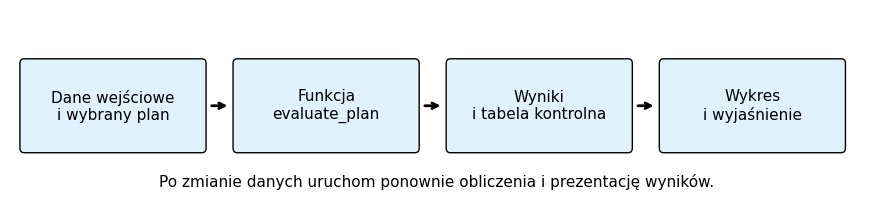

In [62]:
# Narysuj łańcuch zależności: zmiana danych wymaga przeliczenia zależnych wyników.
fig, ax = plt.subplots(figsize=(11, 2.5))
ax.set(xlim=(0, 12), ylim=(0, 2.5))
ax.axis("off")
labels = ["Dane wejściowe\ni wybrany plan", "Funkcja\nevaluate_plan", "Wyniki\ni tabela kontrolna", "Wykres\ni wyjaśnienie"]
for i, label in enumerate(labels):
    # enumerate podaje zarówno pozycję i, jak i bieżącą etykietę.
    x = 0.2 + 3 * i
    ax.add_patch(FancyBboxPatch((x, 0.7), 2.5, 1.1,
                               boxstyle="round,pad=0.06", facecolor="#e0f2fe"))
    ax.text(x + 1.25, 1.25, label, ha="center", va="center", fontsize=11)
    if i < len(labels) - 1:
        ax.annotate("", xy=(x + 2.9, 1.25), xytext=(x + 2.6, 1.25),
                    arrowprops={"arrowstyle": "->", "lw": 2})
ax.text(6, 0.2, "Po zmianie danych uruchom ponownie obliczenia i prezentację wyników.",
        ha="center", fontsize=11)
plt.show()

## Wynik końcowy: pierwsza notatka o planie produkcji

Oddaj notebook działający w świeżym środowisku, zawierający:

1. Odpowiedzi na zadania kontrolne A–E, w tym przewidywania i wyjaśnienia.
2. Tabelę porównującą trzy plany, w tym jeden niedopuszczalny.
3. Jeden rekomendowany plan dopuszczalny, jego zysk w PLN i luz obu ograniczeń w minutach.
4. Opisany wykres zużycia zasobów dla rekomendowanego planu.
5. Wyjaśnienie w 3–5 zdaniach: co obliczył Python, co wybrałeś samodzielnie i co wniósłby solver?

**DO ZROBIENIA: kontrola końcowa.** Uruchom ponownie środowisko lub kernel, a następnie wszystkie komórki. Jeśli rozwiązanie działa tylko przy przypadkowej kolejności klikania, popraw kolejność albo zdefiniuj brakujące zmienne przed oddaniem.

**Rozszerzenie opcjonalne:** za pomocą zagnieżdżonych pętli wylicz plany całkowitoliczbowe z liczbą Mini od 0 do 17 oraz Pro od 0 do 8. Sprawdź każdy plan, zachowaj dopuszczalne i porównaj zyski. Te zakresy obejmują wszystkie dopuszczalne nieujemne plany produkcji całych zestawów przy bazowym limicie montażu. Wyjaśnij, dlaczego wyliczanie staje się niewygodne przy wielu produktach i czym różni się od optymalizacji ciągłego LP, który pozwala na ilości ułamkowe.

**Dalej, laboratorium 1:** zachowaj te same nawyki — jawne dane, jednostki, kontrole, tabele i wykresy — ale zastąp wybrane ilości zmiennymi decyzyjnymi PuLP.